# Исследование морских черепах. Линейная регрессия для определения массы



Необходимо реализовать модель  для определения массы морских черепах на основе других данных: возраста, размеров, числа колец.

Некоторые данные могут потребовать обработки.

## Постановка задачи машинного обучения

- Опишите, какую задачу нужно решить: регрессии или классификации.
- Выберите поле, которое станет целевой переменной.
- Назовите метрики качества модели, которые планируете использовать.
- Опишите критерии успешности проекта с опорой на метрики.

Необходимо решить задачу линейной регрессии.

Целевая переменная weight - масса  морской черепахи.

Планируем использовать метрики качества: MAE - основная , дополнительные MAPE, MSE, R2.

Критерии успешности:
- приемлемая метрика MAE в случае взрослых особей — не более 5 кг;
- R² - не меньше 0.97.

## Подключение и настройка библиотек

В блоке кода ниже, помимо уже указанных библиотек, импортируйте все остальные, которые планируете использовать для проекта.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Загрузка датасета

- Загрузите данные из файла `turtles.csv`, путь к файлу: `'/datasets/turtles.csv'`. При использовании метода [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) установите правильные значения для параметров `sep` и `decimal`: в качестве разделителя столбцов используйте символ табуляции (`'\t'`), а в качестве разделителя дробной части — запятую.
- Проверьте, правильно ли прошла загрузка. Данные должны соответствовать описанию в тексте урока.
- С помощью методов библиотеки pandas выведите общие сведения о данных.
- Возможно ли продолжать работу? Если нет — что нужно сделать, чтобы устранить препятствия?

In [10]:
try:
    df_raw = pd.read_csv('datasets/turtles.csv', sep='\t', decimal=',')
except Exception as e:
    df_raw = pd.read_csv('/datasets/turtles.csv', sep='\t', decimal=',')

display(df_raw.info())
display(df_raw.head(5))

<class 'pandas.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   8861 non-null   int64  
 1   binomial_name        8812 non-null   str    
 2   registration number  8832 non-null   str    
 3   shell_length         8774 non-null   float64
 4   shell_width          8861 non-null   int64  
 5   head_length          8715 non-null   float64
 6   head_width           8715 non-null   float64
 7   flipper_length_1     8861 non-null   int64  
 8   flipper_width_1      8861 non-null   int64  
 9   flipper_length_2     8861 non-null   int64  
 10  flipper_width_2      8861 non-null   int64  
 11  flipper_length_3     8760 non-null   float64
 12  flipper_width_3      8760 non-null   float64
 13  flipper_length_4     8760 non-null   float64
 14  flipper_width_4      8760 non-null   float64
 15  circle_count         8861 non-null   int64  
 16 

None

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511


### Выводы по полученнным данным
Данные соответствуют заявленным в задании.

Присутствуют пропуски практически во всех столбцах - потребуется обработка

## Исследовательский анализ данных

Проведите исследовательский анализ данных:
1. Выясните, данные о каких черепахах представлены в датасете.
2. Проведите отбор записей о нужном виде черепах. Для дальнейшей работы достаточно изучить только *Chelonia mydas*. При этом вы можете сравнить распределение данных об этих черепахах с другими видами, если есть желание и время.
3. Определите, все ли признаки можно использовать для решения задачи. Ответ обоснуйте. Удалите признаки, которые вам никак не помогут.
4. Проверьте, есть ли в данных пропуски. Определите, какие из них можно обработать сразу, а в каких случаях лучше сперва провести разделение на выборки. Решите, стоит ли удалить некоторые пропуски.
5. Определите, есть ли в данных дубликаты. Выберите корректный способ их обработки.
6. Проанализируйте распределение признаков, постройте необходимые для этого визуализации: ящики с усами, гистограммы и так далее. Определите, есть ли в данных выбросы и какие из них критичные. Решите, можно ли их сразу исправить.
7. Проверьте, одинаков ли масштаб признаков. Если он различается, предложите решение этой проблемы.
8. Проанализируйте корреляцию между признаками и целевой переменной с помощью вычислений и графически. Определите, все ли признаки нужны для дальнейшей работы.
9. Проверьте данные на мультиколлинеарность и решите, можно ли её устранить.

In [19]:
# Посмотрим сколько видов черепах есть, отберем Chelonia mydas, посмотрим как изменился 
print("Уникальные виды черепах и их количество:")
display(df_raw['binomial_name'].value_counts(dropna=False))


Уникальные виды черепах и их количество:


binomial_name
Lepidochelys olivacea     3372
Chelonia mydas            2325
Caretta caretta            674
lepidochelys olivacea      416
Dermochelys coriacea       399
Eretmochelys imbricata     332
Lepidochelys Olivacea      285
chelonia mydas             252
Chelonia Mydas             177
LEPIDOCHELYS OLIVACEA      142
caretta caretta             90
CHELONIA MYDAS              75
NaN                         49
Caretta Caretta             46
eretmochelys imbricata      41
dermochelys coriacea        40
CARETTA CARETTA             37
Eretmochelys Imbricata      28
Dermochelys Coriacea        27
Lepidochelys kempii         22
DERMOCHELYS CORIACEA        18
ERETMOCHELYS IMBRICATA       8
lepidochelys kempii          3
Lepidochelys Kempii          3
Name: count, dtype: int64

In [24]:
# Ввиду различных наименований нужных черепах проведём прведение к единому виду
# Посмотрим на все уникальные варианты написания, содержащие "chelonia"
variants = df_raw['binomial_name'].dropna().unique()
chelonia_variants = [v for v in variants if 'chelonia' in v.lower()]

print("Варианты написания, содержащие 'chelonia':")
for v in chelonia_variants:
    print(f"  {repr(v)}")
    
df_green = df_raw[df_raw['binomial_name'].str.lower() == 'chelonia mydas']
display(df_green.info())

print(f"Размер датасета уменьшилмя в {round(len(df_raw) / len(df_green), 1)} раз.")

Варианты написания, содержащие 'chelonia':
  'Chelonia mydas'
  'chelonia mydas'
  'Chelonia Mydas'
  'CHELONIA MYDAS'
<class 'pandas.DataFrame'>
Index: 2829 entries, 8 to 8859
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   2829 non-null   int64  
 1   binomial_name        2829 non-null   str    
 2   registration number  2825 non-null   str    
 3   shell_length         2794 non-null   float64
 4   shell_width          2829 non-null   int64  
 5   head_length          2790 non-null   float64
 6   head_width           2790 non-null   float64
 7   flipper_length_1     2829 non-null   int64  
 8   flipper_width_1      2829 non-null   int64  
 9   flipper_length_2     2829 non-null   int64  
 10  flipper_width_2      2829 non-null   int64  
 11  flipper_length_3     2798 non-null   float64
 12  flipper_width_3      2798 non-null   float64
 13  flipper_length_4     2798 non-null 

None

Размер датасета уменьшилмя в 3.1 раз.


проведём осмотр сомнительных для анализа колонок: 'measure_count', 'shell_crack', 'timestamp'

In [25]:
def describe_column(df, col):
    """Выводит краткую сводку по колонке: тип, пропуски, уникальные значения."""
    print(f"=== {col} ===")
    print(f"Тип: {df[col].dtype}")
    print(f"Пропусков: {df[col].isna().sum()} ({df[col].isna().mean():.1%})")
    print(f"Уникальных значений: {df[col].nunique()}")
    if df[col].nunique() <= 10:
        print("Значения:")
        print(df[col].value_counts(dropna=False))
    else:
        print(df[col].describe())
    print()

# Проверим три спорных признака
for col in ['measure_count', 'shell_crack', 'timestamp']:
    describe_column(df_green, col)

=== measure_count ===
Тип: float64
Пропусков: 81 (2.9%)
Уникальных значений: 4
Значения:
measure_count
3.0    729
1.0    685
2.0    675
4.0    659
NaN     81
Name: count, dtype: int64

=== shell_crack ===
Тип: float64
Пропусков: 2152 (76.1%)
Уникальных значений: 5
Значения:
shell_crack
NaN    2152
1.0     440
2.0      89
3.0      67
5.0      56
4.0      25
Name: count, dtype: int64

=== timestamp ===
Тип: int64
Пропусков: 0 (0.0%)
Уникальных значений: 2488
count    2.829000e+03
mean     1.712264e+09
std      2.289920e+07
min      1.672570e+09
25%      1.692143e+09
50%      1.712771e+09
75%      1.732321e+09
max      1.751588e+09
Name: timestamp, dtype: float64



In [26]:
# 1. Корреляция measure_count с weight
print("Корреляция measure_count и weight:")
print(df_green[['measure_count', 'weight']].corr().iloc[0, 1])
print()

# 2. Timestamp по месяцам
df_green['date'] = pd.to_datetime(df_green['timestamp'], unit='s')
print("Распределение по месяцам:")
print(df_green['date'].dt.to_period('M').value_counts().sort_index())
print()

# 3. Пропуски в оставшихся колонках
print("Пропуски по колонкам:")
print(df_green.isna().sum().sort_values(ascending=False).head(10))
print()

# 4. Дубликаты
print(f"Дубликатов по id: {df_green['id'].duplicated().sum()}")
print(f"Дубликатов по registration number: {df_green['registration number'].duplicated().sum()}")

Корреляция measure_count и weight:
-0.03991545567209781

Распределение по месяцам:
date
2023-01     84
2023-02     88
2023-03    114
2023-04     83
2023-05     95
2023-06     87
2023-07    107
2023-08    100
2023-09     81
2023-10    106
2023-11     96
2023-12     95
2024-01     90
2024-02     95
2024-03     72
2024-04     89
2024-05     96
2024-06     89
2024-07    106
2024-08     77
2024-09    104
2024-10     99
2024-11     90
2024-12     93
2025-01    123
2025-02     90
2025-03     93
2025-04     87
2025-05     97
2025-06     89
2025-07     14
Freq: M, Name: count, dtype: int64

Пропуски по колонкам:
shell_crack            2152
measure_count            81
head_length              39
head_width               39
shell_length             35
flipper_length_4         31
flipper_width_4          31
flipper_length_3         31
flipper_width_3          31
registration number       4
dtype: int64

Дубликатов по id: 341
Дубликатов по registration number: 344


### Работа с дубликатами


In [27]:
# Найдём registration_number, который встречается чаще всего
top_dup = df_green['registration number'].value_counts().head()
print("Топ повторяющихся registration number:")
print(top_dup)
print()

# Посмотрим на все строки одной такой черепахи
dup_id = top_dup.index[0]
display(df_green[df_green['registration number'] == dup_id][
    ['id', 'registration number', 'shell_length', 'weight', 'date']
].sort_values('date'))

Топ повторяющихся registration number:
registration number
754c28373496ea3b28a749b9453c213f    2
468b5d80c4802bc4725e2503d461f9ce    2
43a5e4ab079a0f821a603cab465320e8    2
359aa4775a1647ee0046fd6adbe5c9ff    2
da14f5e84d32970d48749596d2e12040    2
Name: count, dtype: int64



,id,registration number,shell_length,weight,date
6823,20833,754c28373496ea3b28a749b9453c213f,NaN,81.789,2024-02-05 20:11:52
7842,20833,754c28373496ea3b28a749b9453c213f,NaN,81.789,2024-02-05 20:11:52


Похоже что дубликаты - техническое задвоение записей.

In [28]:
# Проверим: есть ли черепахи с РАЗНЫМИ датами измерений
dup_regs = df_green[df_green['registration number'].duplicated(keep=False)]
print(f"Всего строк с дублирующимися registration number: {len(dup_regs)}")

# Для каждой такой черепахи посмотрим, сколько у неё уникальных дат
unique_dates_per_turtle = dup_regs.groupby('registration number')['date'].nunique()
print("\nСколько уникальных дат у черепах с дубликатами:")
print(unique_dates_per_turtle.value_counts())

# Если у всех 1 уникальная дата — это полные дубликаты
# Если есть 2+ — это реальные повторные измерения

Всего строк с дублирующимися registration number: 686

Сколько уникальных дат у черепах с дубликатами:
date
1    341
Name: count, dtype: int64


У всех - просто задвоение записей (у 4-х может быть затроение). Удалим эти дубликаты чтобы избежать утечки данных.

Проверим влияние даты (месяца) на результаты измерений..

In [30]:
print("Средняя масса по кварталам:")
print(df_green.groupby(df_green['date'].dt.to_period('Q'))['weight'].mean().round(2))

Средняя масса по кварталам:
date
2023Q1     91.90
2023Q2     97.30
2023Q3     94.51
2023Q4     94.46
2024Q1     96.31
2024Q2     96.69
2024Q3     95.16
2024Q4     96.60
2025Q1    100.98
2025Q2     97.33
2025Q3     85.81
Freq: Q-DEC, Name: weight, dtype: float64


Время тоже не влияет на измеренные значения. Проведём удаление дубликатов и подготовку рабочих колонок.

In [31]:
# 1. Удаляем дубликаты
print(f"Размер до удаления дубликатов: {len(df_green)}")
df_green = df_green.drop_duplicates(subset='id').reset_index(drop=True)
print(f"Размер после удаления дубликатов: {len(df_green)}")
print()

# 2. Удаляем ненужные колонки
cols_to_drop = [
    'id', 'binomial_name', 'registration number',
    'measure_count', 'shell_crack', 'timestamp', 'date'
]
df_model = df_green.drop(columns=cols_to_drop)
print(f"Признаки для модели: {df_model.columns.tolist()}")
print(f"Размер датасета: {df_model.shape}")
print()

# 3. Проверяем пропуски в оставшихся колонках
print("Пропуски в признаках модели:")
print(df_model.isna().sum().sort_values(ascending=False))

Размер до удаления дубликатов: 2488
Размер после удаления дубликатов: 2488

Признаки для модели: ['shell_length', 'shell_width', 'head_length', 'head_width', 'flipper_length_1', 'flipper_width_1', 'flipper_length_2', 'flipper_width_2', 'flipper_length_3', 'flipper_width_3', 'flipper_length_4', 'flipper_width_4', 'circle_count', 'weight']
Размер датасета: (2488, 14)

Пропуски в признаках модели:
head_width          35
head_length         35
shell_length        29
flipper_width_4     29
flipper_length_3    29
flipper_width_3     29
flipper_length_4    29
weight               2
shell_width          0
flipper_length_1     0
flipper_width_1      0
flipper_width_2      0
flipper_length_2     0
circle_count         0
dtype: int64


Удаляем пропуски

In [32]:
# 1. Удаляем строки с пропуском в целевой переменной (weight)
df_model = df_model.dropna(subset=['weight'])

# 2. Удаляем строки с пропусками в признаках
print(f"Размер до очистки: {len(df_model)}")
df_model = df_model.dropna()
print(f"Размер после очистки: {len(df_model)}")
print(f"Потеряно строк: {2488 - len(df_model)} ({((2488 - len(df_model)) / 2488):.1%})")

# 3. Проверяем, что пропусков не осталось
print(f"\nВсего пропусков после очистки: {df_model.isna().sum().sum()}")

Размер до очистки: 2486
Размер после очистки: 2396
Потеряно строк: 92 (3.7%)

Всего пропусков после очистки: 0


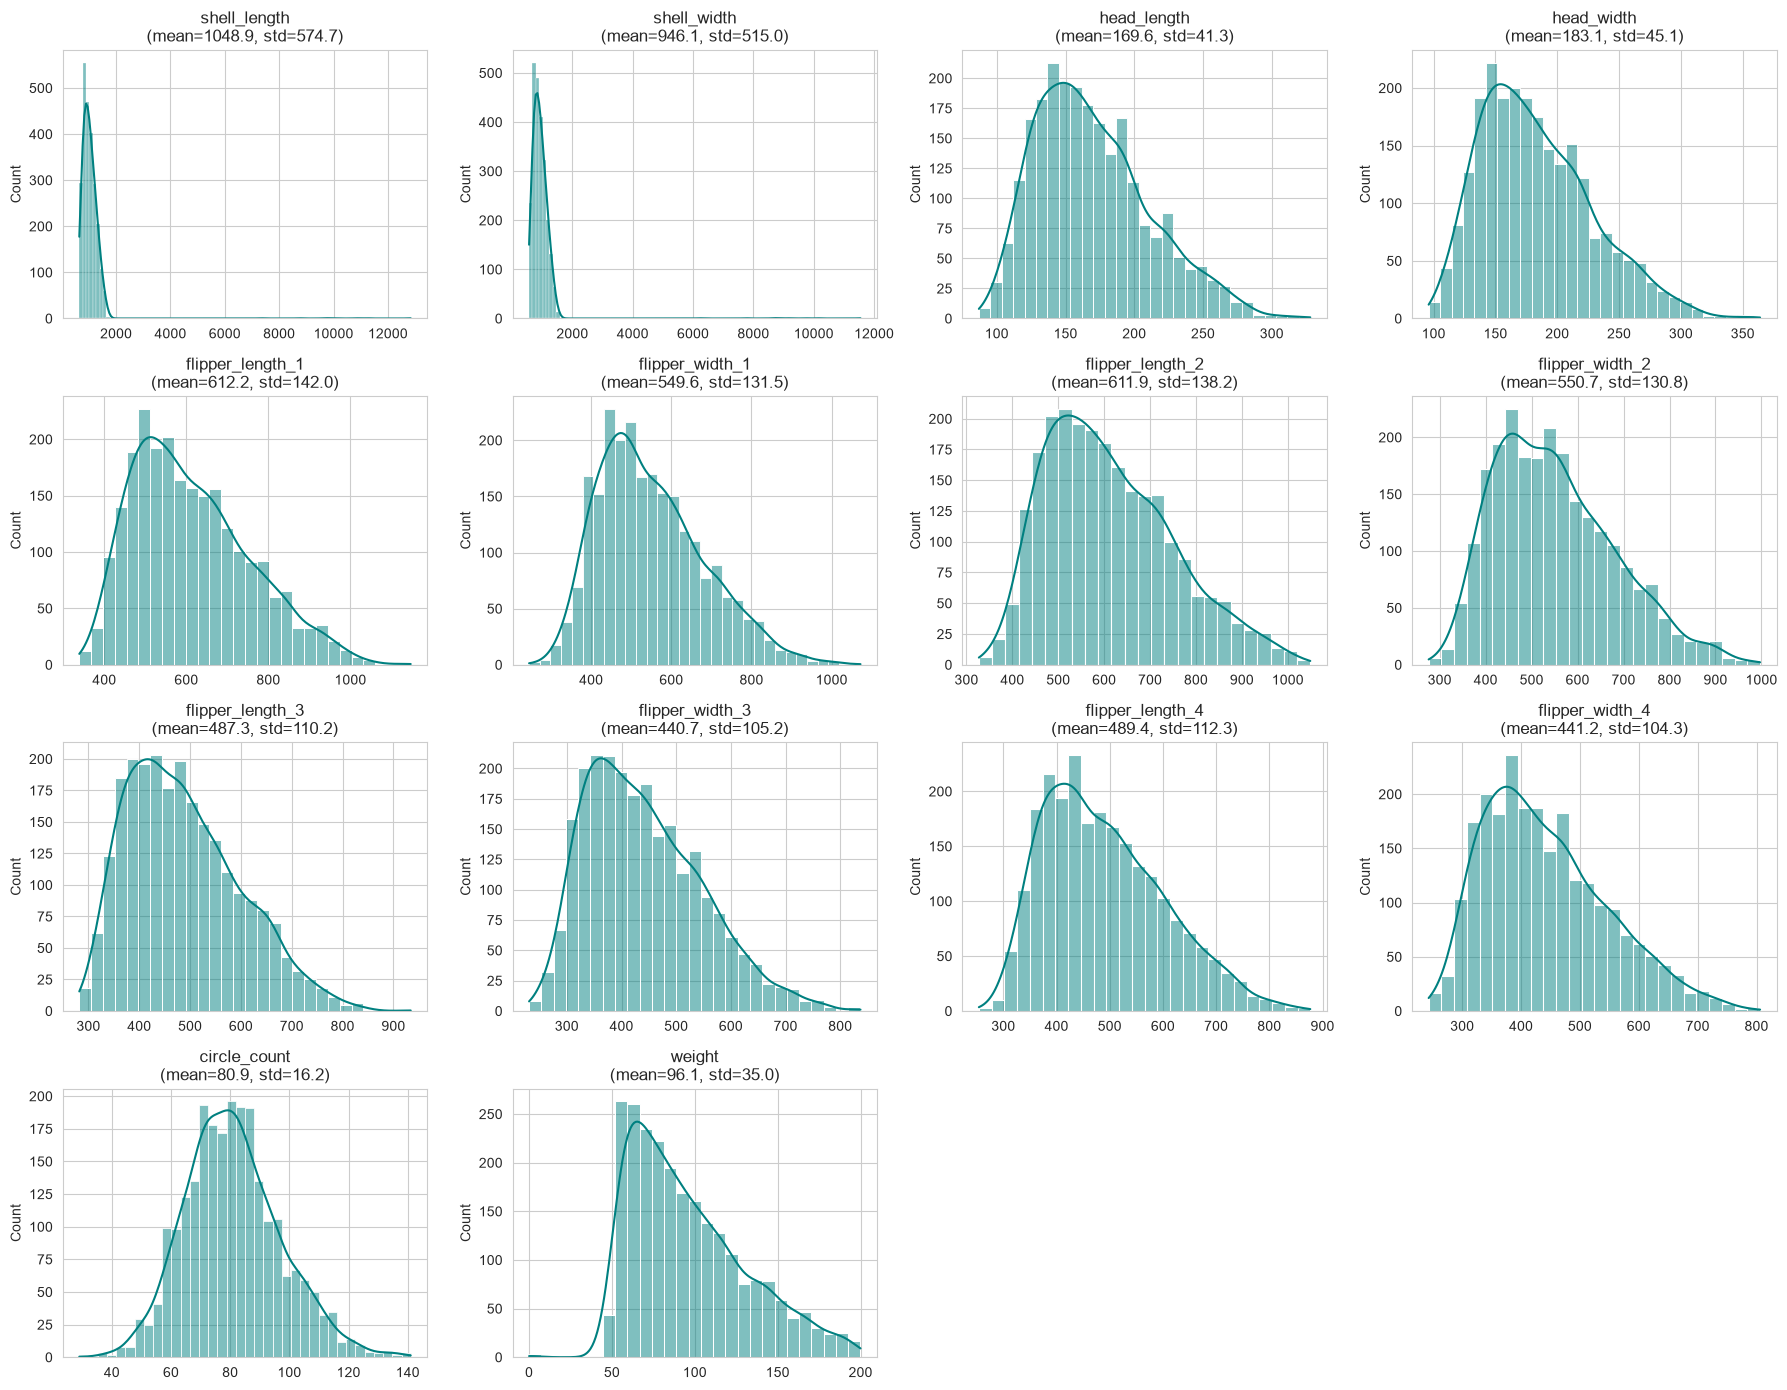

In [35]:
# Настройка стиля
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 10)

# 1. Гистограммы всех признаков + целевой переменной
features = df_model.drop(columns=['weight']).columns.tolist()

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(df_model.columns):
    sns.histplot(df_model[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'{col}\n(mean={df_model[col].mean():.1f}, std={df_model[col].std():.1f})')
    axes[i].set_xlabel('')

# Скрываем пустые графики
for j in range(len(df_model.columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

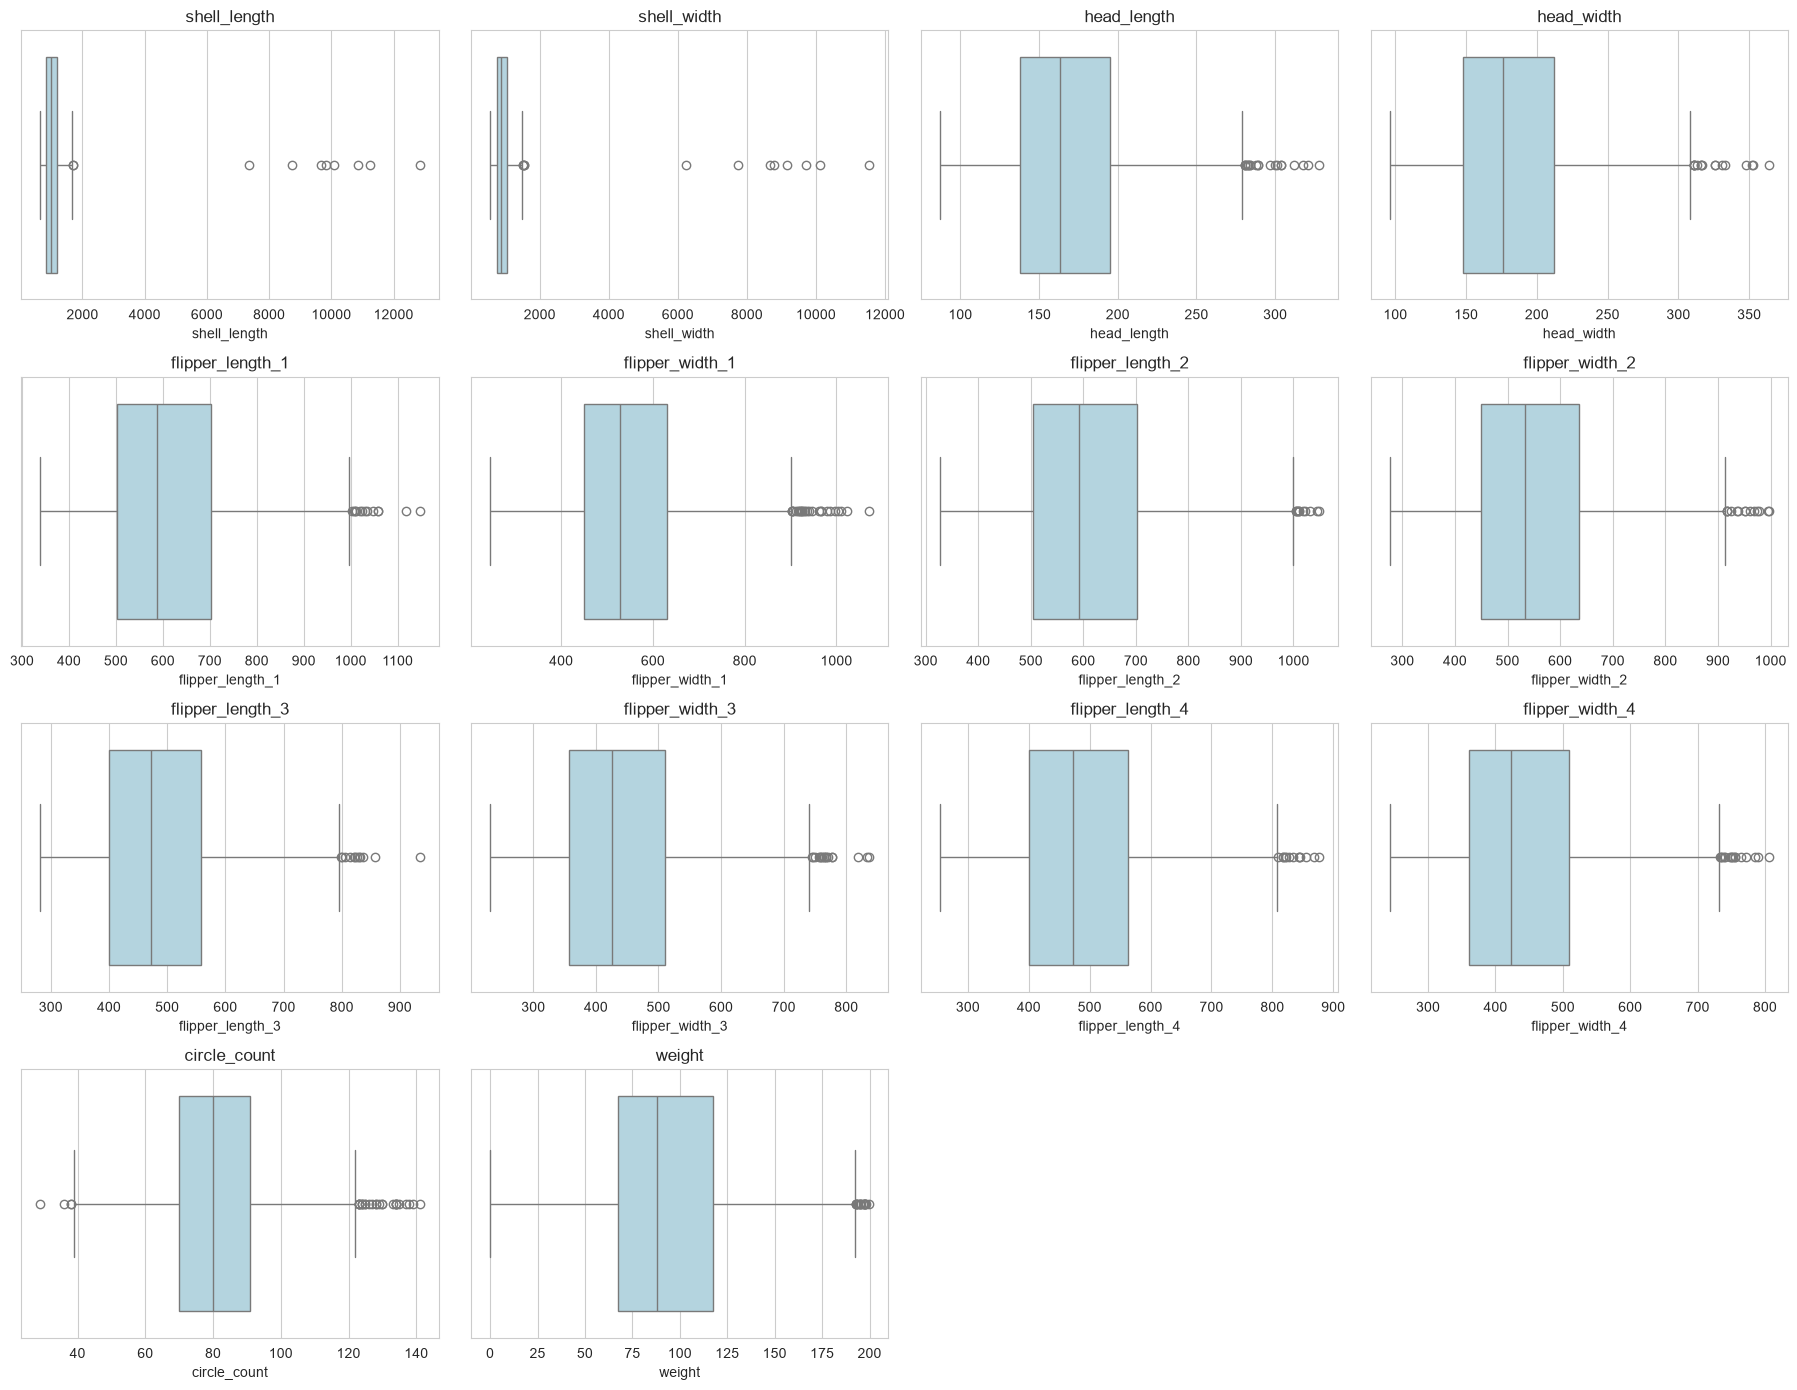

In [36]:
# 2. Boxplot для всех признаков
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(df_model.columns):
    sns.boxplot(x=df_model[col], ax=axes[i], color='lightblue')
    axes[i].set_title(col)

for j in range(len(df_model.columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [37]:
# 3. Описательная статистика
display(df_model.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
shell_length,2396.0,1048.94,574.73,645.0,837.00,980.50,1170.50,12840.00
shell_width,2396.0,946.11,514.99,564.0,755.00,890.00,1055.00,11550.00
head_length,2396.0,169.60,41.30,87.0,138.00,163.00,195.00,328.00
head_width,2396.0,183.05,45.09,96.0,148.00,176.00,212.00,364.00
flipper_length_1,2396.0,612.15,141.96,339.0,502.00,588.00,702.00,1147.00
flipper_width_1,2396.0,549.55,131.52,245.0,450.00,528.00,631.00,1072.00
flipper_length_2,2396.0,611.88,138.17,327.0,505.00,591.00,703.00,1049.00
flipper_width_2,2396.0,550.73,130.77,276.0,449.00,533.50,635.25,997.00
flipper_length_3,2396.0,487.27,110.17,282.0,400.00,473.00,558.00,934.00
flipper_width_3,2396.0,440.65,105.24,231.0,357.00,426.00,511.00,837.00


В данных по панцирям - явные ошибки - то что волонтёр умножил на 10. Найдём и поправим. Размер > 2000 мм - предельный (https://ru.wikipedia.org/wiki/%D0%97%D0%B5%D0%BB%D1%91%D0%BD%D0%B0%D1%8F_%D1%87%D0%B5%D1%80%D0%B5%D0%BF%D0%B0%D1%85%D0%B0)

In [38]:
# Посмотрим на распределение shell_length и shell_width
print("shell_length: значения > 2000 мм")
print(df_model[df_model['shell_length'] > 2000]['shell_length'].describe())
print(f"Количество: {(df_model['shell_length'] > 2000).sum()}")
print()

print("shell_width: значения > 2000 мм")
print(df_model[df_model['shell_width'] > 2000]['shell_width'].describe())
print(f"Количество: {(df_model['shell_width'] > 2000).sum()}")

shell_length: значения > 2000 мм
count        8.000000
mean     10076.250000
std       1651.059725
min       7340.000000
25%       9432.500000
50%       9960.000000
75%      10955.000000
max      12840.000000
Name: shell_length, dtype: float64
Количество: 8

shell_width: значения > 2000 мм
count        8.000000
mean      8993.750000
std       1589.365889
min       6230.000000
25%       8432.500000
50%       8965.000000
75%       9812.500000
max      11550.000000
Name: shell_width, dtype: float64
Количество: 8


In [39]:
# Исправляем: делим на 10 значения > 2000
print(f"До исправления:")
print(f"  shell_length max: {df_model['shell_length'].max()}")
print(f"  shell_width max: {df_model['shell_width'].max()}")
print()

# Исправление
mask_length = df_model['shell_length'] > 2000
mask_width = df_model['shell_width'] > 2000

print(f"Исправляем {mask_length.sum()} значений в shell_length")
print(f"Исправляем {mask_width.sum()} значений в shell_width")

df_model.loc[mask_length, 'shell_length'] /= 10
df_model.loc[mask_width, 'shell_width'] /= 10

print(f"\nПосле исправления:")
print(f"  shell_length max: {df_model['shell_length'].max():.1f}")
print(f"  shell_width max: {df_model['shell_width'].max():.1f}")
print()
print("Новая статистика:")
display(df_model[['shell_length', 'shell_width']].describe().T.round(2))

До исправления:
  shell_length max: 12840.0
  shell_width max: 11550

Исправляем 8 значений в shell_length
Исправляем 8 значений в shell_width

После исправления:
  shell_length max: 1683.0
  shell_width max: 1554.0

Новая статистика:


,count,mean,std,min,25%,50%,75%,max
shell_length,2396.0,1018.66,222.05,645.0,837.00,980.0,1167.0,1683.0
shell_width,2396.0,919.09,202.13,564.0,754.75,889.0,1054.0,1554.0


И нулевая масса (weight = 0)

In [40]:
# Найдём строки с аномальной массой
print(f"Строк с weight == 0: {(df_model['weight'] == 0).sum()}")
print(f"Строк с weight < 10: {(df_model['weight'] < 10).sum()}")
print(f"Строк с weight > 150: {(df_model['weight'] > 150).sum()}")

# Посмотрим на подозрительные строки
display(df_model[df_model['weight'] < 10])

Строк с weight == 0: 3
Строк с weight < 10: 3
Строк с weight > 150: 221


,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,weight
278,1506.0,1341,262.0,265.0,979,777,910,732,728.0,651.0,604.0,676.0,109,0.0
1012,780.0,797,145.0,150.0,539,426,536,513,399.0,388.0,361.0,369.0,70,0.0
1558,892.0,826,124.0,158.0,543,482,517,528,431.0,442.0,448.0,377.0,83,0.0


Удалим черепах с нулевой массой

Пересчитаем выбросы


## Предобработка данных

In [43]:
print(f"Размер до удаления: {len(df_model)}")
df_model = df_model[df_model['weight'] > 0].reset_index(drop=True)
print(f"Размер после удаления: {len(df_model)}")
print("Что видим:")
display(df_model['weight'].describe().round(2))

Размер до удаления: 2393
Размер после удаления: 2393
Что видим:


count    2393.00
mean       96.17
std        34.84
min        49.04
25%        67.62
50%        88.23
75%       117.56
max       199.96
Name: weight, dtype: float64

1. Разделите данные на выборки: обучающую (60%), валидационную (20%) и тестовую (20%). В реальных проектах стараются писать код предобработки так, чтобы предотвратить утечку данных. Это проще сделать, если сразу поделить данные.
2. Обработайте пропуски. При необходимости заполните их средними (медианными) значениями. Рассчитайте заполнитель только по обучающей выборке: это ещё одно правило для предотвращения утечки.
3. Напишите функцию для стандартизации признаков. Расчёт параметров масштабирования делайте только по обучающей выборке, чтобы не дать утечке ни малейшего шанса.
4. Напишите функцию для нормализации признаков.
5. Подготовьте несколько датасетов из трёх выборок каждый для дальнейшего обучения моделей с разным способом масштабирования: без масштабирования, с нормализацией, со стандартизацией.

## Обучение моделей

1. Постройте базовую модель (дамми), с которой будете сравнивать все остальные. Если они будут хуже базовой по качеству, это будет означать, что при обучении что-то пошло не так. Пример дамми: модель, которая всегда предсказывает среднее значение целевой переменной из обучающей выборки.
2. Обучите несколько архитектур линейных моделей. Они могут различаться по ряду черт: набором отобранных признаков, масштабом признаков, установленными гиперпараметрами, функциями потерь. Попробуйте обучить следующие модели:
   - `LinearRegression`;
   - `Lasso` (L1-регуляризация);
   - `Ridge` (L2-регуляризация);
   - `SGDRegressor`.
   
   Обязательно попробуйте модели с разными значениями гиперпараметра `loss`.
- **Бонусное задание.** Подумайте, можно ли улучшить модели за счёт создания новых признаков: например, умножив длину ласт на ширину. Проверьте, усилится ли корреляция нового признака с целевой переменной, возрастёт ли благодаря ему качество модели.
3. Сформируйте итоговую таблицу с результатами моделей. Это удобно сделать в виде датафрейма pandas. Включите в таблицу следующие столбцы:
   - Название модели.
   - Название датасета — оно должно указывать на то, какой способ масштабирования использовался при подготовке данных.
   - Метрики качества, рассчитанные на валидационной выборке. Основная метрика — MAE, дополнительные — MSE, R², MAPE и прочие.

## Сравнение моделей на валидационной выборке

1. Сравните построенные модели по метрикам на валидационной выборке. Удалось ли существенно улучшить результат базовой модели?
2. Выберите лучшую модель по основной метрике на валидационной выборке. Не заглядывайте в метрики на тестовой выборке раньше времени. Тестовая выборка не используется для обучения моделей, подбора гиперпараметров и сравнения моделей с разными значениями.
3. Напишите выводы о том, какая из моделей обладает лучшим качеством. Именно её одну далее нужно проверить на тестовой выборке для итоговой оценки.

## Проверка лучшей модели на тестовой выборке

1. Проверьте метрики лучшей модели на тестовой выборке.
2. Узнайте, есть ли признаки переобучения лучшей модели.
3. Определите, соответствует ли модель требованиям заказчика. Объясните, можно ли её рекомендовать к внедрению.

## Оценка важности признаков

1. Оцените важность признаков по абсолютным значениям весов лучшей модели.
2. Напишите, какие признаки стали для модели более важными. Объясните, согласны ли вы с таким результатом?

## Функция для прогнозирования веса черепахи

* Напишите на Python функцию, которая будет прогнозировать массу черепахи по заданным параметрам с учётом коэффициентов лучшей модели (свойство `coef_`) и смещения (свойство `intercept_`).
* Если вы столкнётесь с трудностями при написании функции, то представьте, что обращаетесь к старшему коллеге с просьбой помочь, и составьте задание для её написания. Подробно опишите логику, по которой рассчитывается масса черепахи, и укажите, как именно должны происходить расчёты.

## Общие выводы и рекомендации по дальнейшей работе

Напишите общие выводы и рекомендации по дальнейшей работе. Ответьте на вопросы:
  - Какие модели изучены?
  - Какие результаты получены?
  - Рекомендуется ли итоговая модель к внедрению?
  - Какая архитектура и способ обработки признаков показали себя лучше всего? Какие у них показатели метрик?
  - Какие признаки наиболее важны для модели?
  - Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?
  - При наличии добавьте сюда свои предложения по дальнейшему развитию проекта.